In [33]:
from langgraph.graph import StateGraph, START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict,Annotated,Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field


In [34]:
load_dotenv()

True

In [35]:
model=ChatGoogleGenerativeAI(model="gemini-3.6-flash")

In [36]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative"] =Field(description="sentiment of the review")


In [37]:
structured_model = model.with_structured_output(SentimentSchema)
# prompt=f"what is the sentiment of following revew - The software is too bad"
# structured_model.invoke(prompt).sentiment



In [38]:
class ReviewState(TypedDict):
    review:str
    sentiment:Literal['postive','negative']
    diagnosis:dict
    response:str

In [39]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned by the user')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone of the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [40]:
structured_model2=model.with_structured_output(DiagnosisSchema)

In [41]:
def find_sentiment(state:ReviewState):
    prompt=f"for the following review find the sentiment {state['review']}"
    sentiment=structured_model.invoke(prompt)
    return {"sentiment":sentiment}

def check_condition(state:ReviewState)->Literal["positive_response", "run_diagnosis"]:
    if state['sentiment'] =="postive":
        return "positive_response"
    else:
        return "run_diagnosis"

In [42]:
def positive_response(state:ReviewState):
    prompt=f"based on the following review give a positive response a warm thankyou {state['review']} also ask for a feedback"
    response=model.invoke(prompt)
    return {"response":response}
def negative_response(state:ReviewState):
    prompt=f"based on the following review give a negative response {state['review']}"
    response=model.invoke(prompt).content
    return {"response":response}
def run_diagnosis(state:ReviewState):
    prompt=f"diagnose the following negative response {state['review']} return issue type , tone and urgency"
    response=structured_model2.invoke(prompt)
    return {"diagnosis":response.model_dump()}

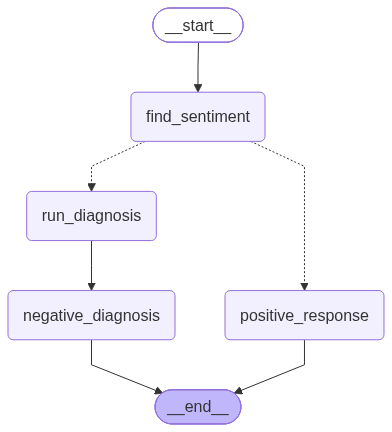

In [43]:
graph= StateGraph(ReviewState)
graph.add_node('find_sentiment',find_sentiment)
graph.add_node('positive_response',positive_response)
graph.add_node('run_diagnosis',run_diagnosis)
graph.add_node('negative_diagnosis',negative_response)


graph.add_edge(START,'find_sentiment')
graph.add_conditional_edges('find_sentiment',check_condition)
graph.add_edge('run_diagnosis', 'negative_diagnosis')
graph.add_edge('positive_response', END)
graph.add_edge('negative_diagnosis', END)
# graph.add_edge(START, 'find_sentiment')

# graph.add_conditional_edges(
#     'find_sentiment',
#     check_condition,
#     {
#         'positive': 'positive_response',
#         'negative': 'run_diagnosis'
#     }
# )

# graph.add_edge('run_diagnosis', 'negative_diagnosis')
# graph.add_edge('positive_response', END)
# graph.add_edge('negative_diagnosis', END)



workflow=graph.compile()
workflow

In [44]:
# Positive review
initial_state = {
    "review": "The app is excellent. It is fast, clean, and very easy to use."
}

result = workflow.invoke(initial_state)
print(result)

{'review': 'The app is excellent. It is fast, clean, and very easy to use.', 'sentiment': SentimentSchema(sentiment='positive'), 'diagnosis': {'issue_type': 'Other', 'tone': 'calm', 'urgency': 'low'}, 'response': [{'type': 'text', 'text': '"I couldn\'t disagree more. The app is terrible—it is extremely slow, cluttered, and very difficult to use."', 'extras': {'signature': 'EpYUCpMUAWkUfRMib/zIXnb4fa6vkXTU3blahf2+ONbeYO3a9otjWfvU+0BllFx+n3dzMtheRU2iWhfxNhnl8SaCorKPYBU2XZF33n12VIyK1BmAf2GASFyyppxiJ+mgC3PgD5RFemBaUT+uBvJrUpbUYroLAHOq4Vk9xr020MDxmpC0IJxxPPmffAucwCVJkzRT2+PEm6erIyY4lPvUNIiDnf/JozSyCmwAT281SQjIN47UxprcQjRF5aEzei4C9d0hqJHJk+7E4tgofT/HAHYqwprqDg55TuI8FHzP2LSk2lmmwtJZJ1kl9rvgc4i/MjMJ4SWyBU0Oqf0USFkfMR8WUFk9OFm1UqqdrkY4oZqtlBTiAa/YKVW1DnGEDytAflXtSb7bH7n4YTJXtpOvcQ06dB5A7OY3tj8EdHaCZdoHdg0qkmeJiECI2AehPFAFF6zSVmOwNdCQkGgzIEgErEk/iaURvQT4jmjKYowXFq69qDg1W9PpTuQl1L4RYjOxRhDFsuGEqfD3KubvnvDN37HCICFaCoYMU1vaj0L0J2NL3sXgKapaCZDpIIix9JtxvX5gtphRYPSuNg8mMCV3I/BmrdQOwr+ygfr8VS4uxfSshTow

In [45]:
# Positive review
initial_state = {
    "review": "The app is excellent. It is fast, clean, and very easy to use."
}

result = workflow.invoke(initial_state)
print(result)

{'review': 'The app is excellent. It is fast, clean, and very easy to use.', 'sentiment': SentimentSchema(sentiment='positive'), 'diagnosis': {'issue_type': 'Other', 'tone': 'calm', 'urgency': 'low'}, 'response': [{'type': 'text', 'text': 'Here are a few ways to generate a negative response based on that text:\n\n**Option 1: A disagreement reply (responding to the reviewer)**\n> "I completely disagree. The app constantly crashes, takes forever to load, and is way too confusing to navigate."\n\n**Option 2: An inverted review (flipping the sentiment to negative)**\n> "The app is terrible. It is slow, cluttered, and very difficult to use."', 'extras': {'signature': 'Et4ZCtsZAWkUfRMn69WKDzS+ta1LE35KAkSNKDjHhFI1r6/EAWpod3mZ8vVLiceKscJZfXk1aiXeUCGus2k94d+2quth1V7b2aOtg0tz5duUYrw0uhXS7E6FPu5eqoKChZebSFVzgsmhjsCeI+aopdoVUbviKiZuGD1Qi7mNJ8xB0Dg9OlWLRYtSLqXCeK/0YcCXQ2BNNoIGNfLXE047vpdkc/K2hNH26iY/A0KsmINhlv/GLhDpzaYKhCPFE6A9ylft5yCuD/0wVyGDkDkD1fCBwRV0dm5rD66mWxhSTjuNjyzLb/om3Ig5iMIN1UCkBcP+AKbd

In [ ]:
# Neutral or calm negative review
initial_state = {
    "review": "The dashboard is confusing and support took too long to respond."
}

result = workflow.invoke(initial_state)
print(result)